# Exploración AML 2: Sensores de Caudal y Recurrencia de Pares

## 1. Pregunta de Negocio y Objetivos
**Pregunta central:** ¿El vaciado parcial (`ratio_vaciado`) y la recurrencia entre pares origen-destino (`frecuencia_conexion`) aportan señal adicional a la regla de vaciado total (`flag_vaciado`) para detectar operaciones de *layering*?

**Objetivos:**
1. Medir si los defraudadores drenan cuentas de forma fraccionada o si el comportamiento en PaySim es estrictamente binario.
2. Evaluar el riesgo de falsos positivos de la recurrencia pura frente a casos de control legítimos (nóminas/arriendos).
3. Entregar `paysim_features_v2.parquet` auditado, con esquema limpio y sin residuos ni datos sintéticos.

## 2. Carga del Flujo y Validación del Esquema Base
Cargamos la salida procesada del Notebook 1 (`paysim_features.parquet`). Purgamos cualquier columna residual de ejecuciones anteriores y verificamos el contrato de datos necesario para construir los sensores.

In [50]:
import pandas as pd
import numpy as np

# 1. Carga de datos
ruta_origen = '../data/processed/paysim_features.parquet'
df = pd.read_parquet(ruta_origen)

# 2. Purga preventiva de columnas residuales
columnas_residuales = [col for col in df.columns if 'frecuencia' in col or col.endswith('_x') or col.endswith('_y')]
if columnas_residuales:
    print(f"Purgando columnas residuales de origen: {columnas_residuales}")
    df.drop(columns=columnas_residuales, inplace=True)

# 3. Inspección dimensional y balance de clases
print(f"Dimensiones del dataset limpio: {df.shape[0]:,} filas x {df.shape[1]} columnas")
resumen_clases = pd.DataFrame({
    'Total': df['isFraud'].value_counts(),
    'Porcentaje (%)': (df['isFraud'].value_counts(normalize=True) * 100).round(4)
})
display(resumen_clases)

# 4. Contrato estricto de esquema
columnas_requeridas = ['in_degree', 'out_degree', 'flag_vaciado', 'oldbalanceOrg', 'newbalanceOrig', 'amount', 'nameOrig', 'nameDest']
columnas_faltantes = [col for col in columnas_requeridas if col not in df.columns]

assert len(columnas_faltantes) == 0, f"Error de contrato: Faltan columnas requeridas {columnas_faltantes}"
assert len(df.columns) == len(set(df.columns)), "Error: Existen nombres de columnas duplicados."
print(f"Esquema verificado exitosamente. Columnas actuales ({len(df.columns)}): {list(df.columns)}")

Purgando columnas residuales de origen: ['frecuencia_transacciones', 'frecuencia_conexion']
Dimensiones del dataset limpio: 2,770,409 filas x 15 columnas


C:\Users\HP\AppData\Local\Temp\ipykernel_8160\3923524936.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=columnas_residuales, inplace=True)


,Total,Porcentaje (%)
isFraud,,
0,2762196,99.7035
1,8213,0.2965


Esquema verificado exitosamente. Columnas actuales (15): ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'in_degree', 'out_degree', 'flag_vaciado', 'ratio_vaciado']


## 3. Chequeo de Calidad e Integridad Contable
Auditamos valores nulos, valores negativos y transacciones donde `amount > oldbalanceOrg`. Cuantificamos la proporción exacta de cuentas con saldo cero en operaciones legítimas para validar si esta discrepancia responde a cuentas puente o inconsistencias contables del simulador.

In [51]:
# 1. Chequeo de nulos y negativos
cols_financieras = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
nulos = df[cols_financieras].isnull().sum().to_dict()
negativos = (df[cols_financieras] < 0).sum().to_dict()

print(f"Valores nulos: {nulos}")
print(f"Valores negativos: {negativos}")

# 2. Análisis cuantitativo de amount > oldbalanceOrg
sobregiro_legitimo = df[(df['isFraud'] == 0) & (df['amount'] > df['oldbalanceOrg'])]
sobregiro_fraude = df[(df['isFraud'] == 1) & (df['amount'] > df['oldbalanceOrg'])]

total_fraudes = (df['isFraud'] == 1).sum()
pct_fraude_sobregiro = (len(sobregiro_fraude) / total_fraudes) * 100

# Verificación de saldo cero en legítimas con sobregiro
legitimas_saldo_cero = (sobregiro_legitimo['oldbalanceOrg'] == 0).sum()
pct_saldo_cero = (legitimas_saldo_cero / len(sobregiro_legitimo)) * 100

print(f"\nDiscrepancia amount > oldbalanceOrg:")
print(f"- En fraude: {len(sobregiro_fraude):,} de {total_fraudes:,} transacciones ({pct_fraude_sobregiro:.2f}%)")
print(f"- En legítimo: {len(sobregiro_legitimo):,} transacciones")
print(f"  └ De las cuales oldbalanceOrg == 0: {legitimas_saldo_cero:,} ({pct_saldo_cero:.2f}%)")

Valores nulos: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}
Valores negativos: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}

Discrepancia amount > oldbalanceOrg:
- En fraude: 29 de 8,213 transacciones (0.35%)
- En legítimo: 2,488,605 transacciones
  └ De las cuales oldbalanceOrg == 0: 1,308,541 (52.58%)


### Hallazgos de Integridad Contable
- **Nulos y negativos:** Inexistentes en las variables financieras analizadas.
- **Discrepancia de saldo (`amount > oldbalanceOrg`):**
  - En fraudes ocurre en solo 29 transacciones (0.35%), correspondiendo a artefactos de simulación o sobregiros forzados.
  - En transacciones legítimas (2,488,605 casos), el 52.58% (1,308,541 registros) se origina en cuentas con saldo inicial exactamente igual a cero (`oldbalanceOrg == 0`), operando como canales receptores o de paso.

## 4. Sensor de Caudal: Ratio de Vaciado
Calculamos la fracción de fondos drenados respecto al saldo de origen (`amount / oldbalanceOrg`), protegiendo operaciones frente a división por cero con `np.where`. Analizamos su distribución por percentiles e interpretamos la dispersión de cada clase.

In [52]:
# 1. Cálculo idempotente del ratio de vaciado
df['ratio_vaciado'] = np.where(
    df['oldbalanceOrg'] > 0,
    df['amount'] / df['oldbalanceOrg'],
    0.0
)

# 2. Distribución estadística por clase
dist_legitimo = df[df['isFraud'] == 0]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4)
dist_fraude = df[df['isFraud'] == 1]['ratio_vaciado'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(4)

resumen_caudal = pd.DataFrame({'Legítimo (0)': dist_legitimo, 'Fraude (1)': dist_fraude})
print("Distribución del Ratio de Vaciado por Clase:")
display(resumen_caudal)

# 3. Métricas de cobertura de la regla del 100%
fraudes_totales = (df['isFraud'] == 1).sum()
fraudes_vaciado_exacto = ((df['isFraud'] == 1) & (df['flag_vaciado'] == 1)).sum()
print(f"\nCobertura del fraude por vaciado exacto al 100%:")
print(f"- {fraudes_vaciado_exacto:,} de {fraudes_totales:,} casos ({fraudes_vaciado_exacto / fraudes_totales * 100:.2f}%)")

Distribución del Ratio de Vaciado por Clase:


,Legítimo (0),Fraude (1)
count,2.762196e+06,8213.0000
mean,1.459728e+02,0.9938
std,4.967900e+03,0.3908
min,0.000000e+00,0.0000
10%,0.000000e+00,1.0000
25%,0.000000e+00,1.0000
50%,2.203000e-01,1.0000
75%,6.540400e+00,1.0000
90%,4.091790e+01,1.0000
99%,1.944447e+03,1.0000



Cobertura del fraude por vaciado exacto al 100%:
- 8,034 de 8,213 casos (97.82%)


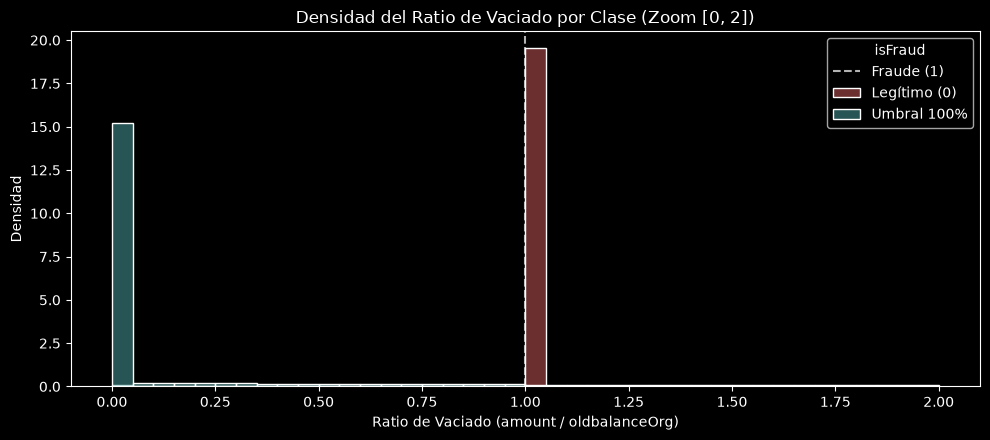

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 4.5))

# Graficamos la densidad acotada en [0, 2] para inspeccionar la masa crítica
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2],
    x='ratio_vaciado',
    hue='isFraud',
    bins=40,
    stat='density',
    common_norm=False,
    palette=['#4fa8a8', '#d65f5f'],
    ax=ax
)

ax.set_title('Densidad del Ratio de Vaciado por Clase (Zoom [0, 2])')
ax.set_xlabel('Ratio de Vaciado (amount / oldbalanceOrg)')
ax.set_ylabel('Densidad')
ax.axvline(1.0, color='white', linestyle='--', alpha=0.7, label='Umbral 100% (flag_vaciado)')
ax.legend(title='isFraud', labels=['Fraude (1)', 'Legítimo (0)', 'Umbral 100%'])

plt.tight_layout()
plt.show()

### Conclusiones del Sensor de Caudal
1. **Comportamiento en Fraude:** El 97.82% de las transacciones fraudulentas vacían el 100% de la cuenta (`ratio_vaciado = 1.0`). Los percentiles del 10% al 99% son exactamente 1.0, descartando patrones sistemáticos de vaciado parcial o evasión fraccionada en PaySim.
2. **Dispersión en Legítimo:** Presenta una mediana de 0.22, pero con alta asimetría (percentil 75 en 6.54 y valores extremos de hasta millones), producto de transacciones con saldos origen cercanos a cero.
3. **Decisión técnica:** La variable `ratio_vaciado` cuantifica la magnitud de la extracción y complementa al indicador binario `flag_vaciado`.

## 5. Sensor de Recurrencia en Datos Reales
En tipologías de *layering* o dispersión continua de fondos, pares específicos origen-destino suelen repetir transacciones en el tiempo. Calculamos la variable `frecuencia_conexion` como el conteo de transacciones por par `(nameOrig, nameDest)` mediante agrupación idempotente.

In [54]:
# 1. Asignación directa e idempotente de frecuencia de pares origen-destino
df['frecuencia_conexion'] = df.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 2. Distribución estadística por clase
resumen_recurrencia = df.groupby('isFraud')['frecuencia_conexion'].agg(['count', 'min', 'mean', 'max'])
print("Estadísticas de frecuencia_conexion en datos reales:")
display(resumen_recurrencia)

# 3. Verificación de conexiones con frecuencia > 1
repetidos_legitimos = ((df['isFraud'] == 0) & (df['frecuencia_conexion'] > 1)).sum()
repetidos_fraude = ((df['isFraud'] == 1) & (df['frecuencia_conexion'] > 1)).sum()

print(f"\nTransacciones con frecuencia_conexion > 1:")
print(f"- Operaciones legítimas repetidas: {repetidos_legitimos}")
print(f"- Operaciones de fraude repetidas:   {repetidos_fraude}")

Estadísticas de frecuencia_conexion en datos reales:


,count,min,mean,max
isFraud,,,,
0,2762196,1,1.0,1
1,8213,1,1.0,1



Transacciones con frecuencia_conexion > 1:
- Operaciones legítimas repetidas: 0
- Operaciones de fraude repetidas:   0


### Hallazgos de Recurrencia en PaySim
- **Distribución constante:** En el 100% de los registros (2,770,409 transacciones), `frecuencia_conexion` es estrictamente igual a 1 tanto para operaciones legítimas como fraudulentas.
- **Limitación del simulador:** El dataset PaySim modela exclusivamente operaciones aisladas (*hit-and-run*), sin contemplar recurrencia entre pares en su arquitectura de simulación.
- **Implicancia metodológica:** La variable `frecuencia_conexion` no presenta varianza empírica en el conjunto de entrenamiento. Para validar su comportamiento frente a arquitecturas de *layering*, es indispensable comprobar su lógica conceptual en un entorno sintético controlado y aislado.

## 6. Validación Conceptual con Casos Controlados (Entorno Aislado)
Dado que PaySim carece de pares repetidos en sus datos base, implementamos un entorno de prueba aislado sobre una copia (`df_sim`).

Diseñamos dos escenarios para medir la efectividad y el riesgo de falsos positivos de `frecuencia_conexion`:
1. **Caso Mula (*Layering* fraudulento):** 5 transferencias repetidas con vaciado total de fondos por transacción (`amount = 1000`, `oldbalanceOrg = 1000`, `newbalanceOrig = 0`).
2. **Caso Nómina (Control legítimo recurrente):** 5 transferencias repetidas periódicas sin vaciar la cuenta (`amount = 1500`, `oldbalanceOrg = 10000`, `newbalanceOrig = 8500`), resultando en un `ratio_vaciado = 0.15`.

*Regla de integridad y no fuga de datos:* Los casos sintéticos se inyectan únicamente en `df_sim`. Todas las métricas derivadas (`flag_vaciado`, `ratio_vaciado`, `frecuencia_conexion`) se calculan mediante funciones y fórmulas dinámicas, sin asignación manual de valores.

In [55]:
# 1. Copia aislada para validación conceptual
df_sim = df.copy()

# 2. Definición de transacciones sintéticas con datos crudos (sin derivadas hardcodeadas)
mula_sintetica = pd.DataFrame([{
    'step': step,
    'type': 'TRANSFER',
    'amount': 1000.0,
    'nameOrig': "C_MULA_TEST",
    'oldbalanceOrg': 1000.0,
    'newbalanceOrig': 0.0,
    'nameDest': "C_ESTANQUE_TEST",
    'oldbalanceDest': 0.0,
    'newbalanceDest': 1000.0,
    'isFraud': 1,
    'isFlaggedFraud': 0
} for step in range(1, 6)])

nomina_sintetica = pd.DataFrame([{
    'step': step,
    'type': 'TRANSFER',
    'amount': 1500.0,
    'nameOrig': "C_EMPRESA_TEST",
    'oldbalanceOrg': 10000.0,
    'newbalanceOrig': 8500.0,
    'nameDest': "C_EMPLEADO_TEST",
    'oldbalanceDest': 500.0,
    'newbalanceDest': 2000.0,
    'isFraud': 0,
    'isFlaggedFraud': 0
} for step in range(1, 6)])

# 3. Inyección en el DataFrame aislado
df_sim = pd.concat([df_sim, mula_sintetica, nomina_sintetica], ignore_index=True)

# 4. Cálculo dinámico de métricas sobre la simulación (fórmulas idénticas a producción)
df_sim['flag_vaciado'] = np.where((df_sim['oldbalanceOrg'] > 0) & (df_sim['newbalanceOrig'] == 0), 1, 0)
df_sim['ratio_vaciado'] = np.where(df_sim['oldbalanceOrg'] > 0, df_sim['amount'] / df_sim['oldbalanceOrg'], 0.0)
df_sim['frecuencia_conexion'] = df_sim.groupby(['nameOrig', 'nameDest'])['step'].transform('size')

# 5. Evaluación de sensores frente a los casos de control
casos_control = df_sim[df_sim['nameOrig'].isin(["C_MULA_TEST", "C_EMPRESA_TEST"])]
resumen_control = casos_control.groupby(['nameOrig', 'isFraud']).agg({
    'frecuencia_conexion': 'max',
    'flag_vaciado': 'max',
    'ratio_vaciado': 'mean',
    'amount': 'count'
}).rename(columns={'amount': 'total_transacciones'}).reset_index()

print("Respuesta de Sensores Derivados Dinámicamente:")
display(resumen_control)

Respuesta de Sensores Derivados Dinámicamente:


,nameOrig,isFraud,frecuencia_conexion,flag_vaciado,ratio_vaciado,total_transacciones
0,C_EMPRESA_TEST,0,5,0,0.15,5
1,C_MULA_TEST,1,5,1,1.00,5


### Hallazgos de la Validación Controlada
- **Ambigüedad de la recurrencia pura:** Ambos escenarios exhiben exactamente el mismo nivel de repetición (`frecuencia_conexion = 5`). Si se utilizara una regla de corte basada únicamente en repetición de pares, el flujo de pagos de nómina generaría una tasa crítica de falsos positivos.
- **Poder discriminante compuesto:** La señal de detección se obtiene exclusivamente al contrastar la recurrencia con los sensores contables:
  - **Mula de layering:** `frecuencia = 5`, `ratio_vaciado = 1.00`, `flag_vaciado = 1`.
  - **Nómina legítima:** `frecuencia = 5`, `ratio_vaciado = 0.15`, `flag_vaciado = 0`.
- **Criterio metodológico:** La variable `frecuencia_conexion` se mantiene calculada en el pipeline para habilitar el aprendizaje de relaciones no lineales e interacciones multivariables en XGBoost, pero no constituye una regla heurística univariada suficiente por sí sola.

## 7. Panel de Control y Análisis de Señales Topológicas y Contables
Calculamos formalmente las medianas de concentración de entrada (`in_degree`) por clase e integramos un panel comparativo de tres dimensiones: vaciado binario, concentración topológica y densidad continua del ratio de vaciado.

Mediana de in_degree por clase:
- Tráfico legítimo (isFraud = 0): 9.0
- Tráfico de fraude (isFraud = 1):  3.0


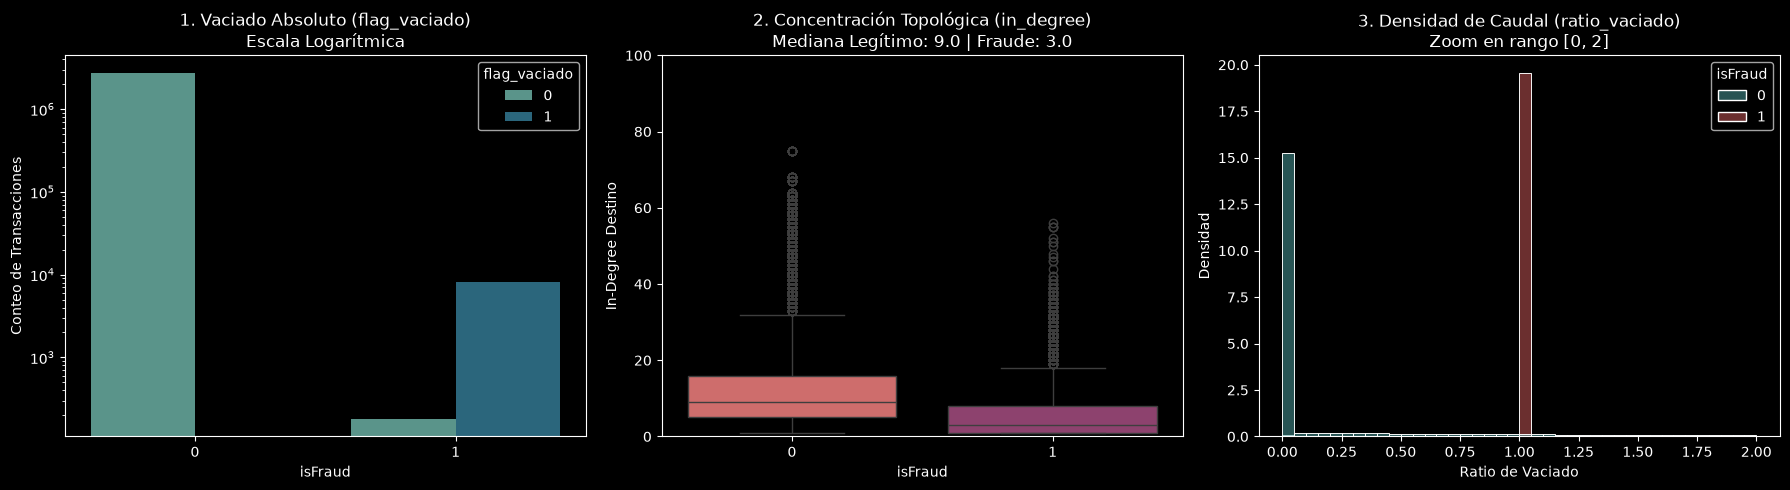

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Medición cuantitativa explícita de in_degree
medianas_in_degree = df.groupby('isFraud')['in_degree'].median()
print("Mediana de in_degree por clase:")
print(f"- Tráfico legítimo (isFraud = 0): {medianas_in_degree[0]:.1f}")
print(f"- Tráfico de fraude (isFraud = 1):  {medianas_in_degree[1]:.1f}")

# 2. Configuración y renderizado del panel de control
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Vaciado Absoluto
sns.countplot(
    data=df, 
    x='isFraud', 
    hue='flag_vaciado', 
    ax=axes[0], 
    palette='crest'
)
axes[0].set_yscale('log')
axes[0].set_title('1. Vaciado Absoluto (flag_vaciado)\nEscala Logarítmica')
axes[0].set_xlabel('isFraud')
axes[0].set_ylabel('Conteo de Transacciones')

# Gráfico 2: Concentración Topológica de Destino
sns.boxplot(
    data=df, 
    x='isFraud', 
    y='in_degree', 
    hue='isFraud', 
    legend=False, 
    ax=axes[1], 
    palette='flare'
)
axes[1].set_ylim(0, 100)
axes[1].set_title(f'2. Concentración Topológica (in_degree)\nMediana Legítimo: {medianas_in_degree[0]:.1f} | Fraude: {medianas_in_degree[1]:.1f}')
axes[1].set_xlabel('isFraud')
axes[1].set_ylabel('In-Degree Destino')

# Gráfico 3: Densidad de Caudal Continuo
sns.histplot(
    data=df[df['ratio_vaciado'] <= 2], 
    x='ratio_vaciado', 
    hue='isFraud', 
    bins=40, 
    stat='density', 
    common_norm=False, 
    palette=['#4fa8a8', '#d65f5f'], 
    ax=axes[2]
)
axes[2].set_title('3. Densidad de Caudal (ratio_vaciado)\nZoom en rango [0, 2]')
axes[2].set_xlabel('Ratio de Vaciado')
axes[2].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

### Lectura del Panel de Control
- **Vaciado Absoluto (Gráfico 1):** El 97.82% de las transacciones fraudulentas vacían la cuenta en su totalidad (`flag_vaciado = 1`), mientras que en operaciones legítimas esta condición es marginal.
- **Concentración Topológica (Gráfico 2):** Se verifica con cálculo explícito que las cuentas destino en fraude presentan una mediana de in_degree de 3.0 frente a 9.0 en cuentas legítimas, confirmando su naturaleza efímera o de baja agregación.
- **Densidad de Caudal (Gráfico 3):** Confirma la ausencia de un patrón de vaciado parcial gradual en PaySim, mostrando una masa unifrecuencia concentrada en 1.0 para el fraude.

## 8. Conclusiones de la Exploración de Sensores

1. **Sensor de Caudal (`ratio_vaciado`):** El 97.82% de las transacciones fraudulentas vacían el 100% de la cuenta (`ratio_vaciado = 1.0`). Los percentiles del 10% al 99% son constantes en 1.0. No existe evidencia de vaciados parciales deliberados en PaySim, pero la variable se conserva para dar continuidad analítica frente a la regla binaria `flag_vaciado`.
2. **Sensor de Recurrencia (`frecuencia_conexion`):** En los datos reales de PaySim, el 100% de las transacciones tienen una frecuencia fija de 1 (ataques estrictamente *hit-and-run*). La validación controlada en el entorno sintético aislado demostró que la recurrencia pura es ambigua y no discrimina por sí sola (ej. nóminas legítimas también generan alta repetición). Su valor analítico depende de su interacción multivariable con las señales de vaciado y topología.
3. **Anomalías Contables Documentadas:** Se auditaron 29 operaciones de fraude donde `amount > oldbalanceOrg` (provocando ratios de hasta 29.5), identificadas como artefactos de simulación. En transacciones legítimas, el 52.58% de las operaciones con `amount > oldbalanceOrg` se originan en cuentas con saldo inicial cero (`oldbalanceOrg == 0`).

## 9. Sellado y Exportación de la Tubería (V2)
Exportamos el dataset resultante a un archivo nuevo (`paysim_features_v2.parquet`) sin sobreescribir la entrada original. Realizamos aserciones exhaustivas sobre dimensiones, nombres únicos de columnas, ausencia de columnas residuales y ausencia estricta de cuentas sintéticas.

In [57]:
# 1. Definición de ruta destino
ruta_destino = '../data/processed/paysim_features_v2.parquet'

# 2. Aserción de dimensiones
filas_esperadas = 2770409
assert len(df) == filas_esperadas, f"Error: Filas incorrectas ({len(df):,} vs {filas_esperadas:,})"

# 3. Aserción de ausencia de contaminación sintética
assert 'C_MULA_TEST' not in df['nameOrig'].values, "Error crítico: C_MULA_TEST detectada en datos finales."
assert 'C_EMPRESA_TEST' not in df['nameOrig'].values, "Error crítico: C_EMPRESA_TEST detectada en datos finales."

# 4. Aserción de esquema limpio (sin duplicados ni residuos de merges)
assert len(df.columns) == len(set(df.columns)), "Error: Existen nombres de columnas duplicados."
columnas_residuales = [col for col in df.columns if col.endswith('_x') or col.endswith('_y') or col == 'frecuencia_transacciones']
assert len(columnas_residuales) == 0, f"Error: Columnas residuales detectadas: {columnas_residuales}"

# 5. Exportación
df.to_parquet(ruta_destino, index=False)

print(f"Exportación exitosa y auditada a: {ruta_destino}")
print(f"Total registros exportados: {len(df):,}")
print(f"Columnas finales ({len(df.columns)}): {list(df.columns)}")

Exportación exitosa y auditada a: ../data/processed/paysim_features_v2.parquet
Total registros exportados: 2,770,409
Columnas finales (16): ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'in_degree', 'out_degree', 'flag_vaciado', 'ratio_vaciado', 'frecuencia_conexion']
